<a href="https://colab.research.google.com/github/AditiAICodes/Wind-turbine-SCADA-analysis/blob/main/Wind_turbine_SCADA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# 1. Load the data
df = pd.read_csv('T1.csv')

# 2. Rename columns
df.columns = ['Date', 'ActivePower', 'WindSpeed', 'TheoreticalPower', 'WindDirection']

In [ ]:
print("🔍 FIRST 5 ROWS ")
display(df.head())

🔍 FIRST 5 ROWS 


,Date,ActivePower,WindSpeed,TheoreticalPower,WindDirection
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645905,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286


In [ ]:
print("\n📊DATA INFO")
df.info()


📊DATA INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50530 entries, 0 to 50529
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              50530 non-null  object 
 1   ActivePower       50530 non-null  float64
 2   WindSpeed         50530 non-null  float64
 3   TheoreticalPower  50530 non-null  float64
 4   WindDirection     50530 non-null  float64
dtypes: float64(4), object(1)
memory usage: 1.9+ MB


In [ ]:
print("\n 📈 STATISTICAL SUMMARY ")
display(df.describe().T)


 📈 STATISTICAL SUMMARY 


,count,mean,std,min,25%,50%,75%,max
ActivePower,50530.0,1307.684332,1312.459242,-2.471405,50.677890,825.838074,2482.507568,3618.732910
WindSpeed,50530.0,7.557952,4.227166,0.000000,4.201395,7.104594,10.300020,25.206011
TheoreticalPower,50530.0,1492.175463,1368.018238,0.000000,161.328167,1063.776283,2964.972462,3600.000000
WindDirection,50530.0,123.687559,93.443736,0.000000,49.315437,73.712978,201.696720,359.997589


In [ ]:
# The Negative Power Fix
# We use .clip() to say: "If a number is lower than 0, just make it 0."
df['ActivePower'] = df['ActivePower'].clip(lower=0)

# The Verification Check
# Count the negative numbers again to prove they are gone
negative_power_count = (df['ActivePower'] < 0).sum()

print(f"Number of rows with Negative Power remaining: {negative_power_count}")

print("New Min of ActivePower:")
print(df['ActivePower'].min())

Number of rows with Negative Power remaining: 0
New Min of ActivePower:
0.0


In [ ]:
import pandas as pd
# THE DATE LOGIC: Convert 'object' to 'datetime'
# Behind the scenes: We are turning a string "01 01 2018" into a 64-bit integer representing nanoseconds since Jan 1, 1970.
# This allows us to do math like (Time_Now - Time_Start).
df['Date'] = pd.to_datetime(df['Date'], format='%d %m %Y %H:%M')

In [ ]:
# Feature Engineering : The Power Loss (Residual)
df['Power_Loss'] = df['TheoreticalPower'] - df['ActivePower']
df.head()

,Date,ActivePower,WindSpeed,TheoreticalPower,WindDirection,Power_Loss
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,36.281117
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,66.148316
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,84.523429
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,96.481664
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,111.052276


🎨 DRAWING THE MACHINE's HEARTBEAT...



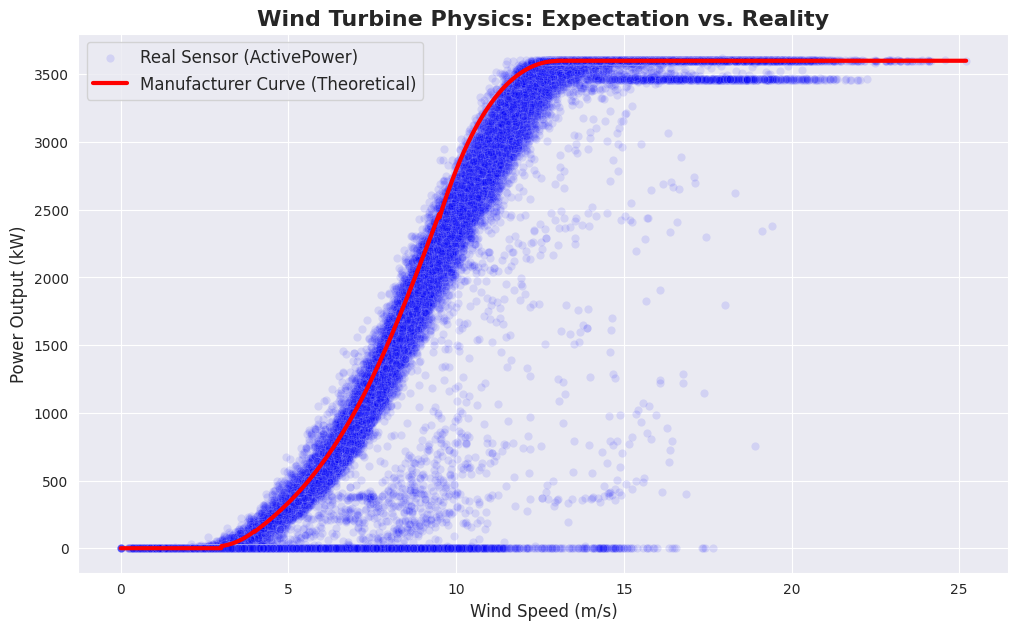

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("🎨 DRAWING THE MACHINE's HEARTBEAT...\n")

plt.figure(figsize=(12, 7))
sns.set_style("darkgrid")

# 1. Plot the Messy Reality (Active Power)
# We use alpha=0.1 to make the dots transparent. Where dots overlap, the color gets darker!
sns.scatterplot(x='WindSpeed', y='ActivePower', data=df,
                color='blue', alpha=0.1, label='Real Sensor (ActivePower)')

# 2. Plot the Physics (Theoretical Power)
# We use a lineplot so it stands out against the scatter of real data
sns.lineplot(x='WindSpeed', y='TheoreticalPower', data=df,
             color='red', linewidth=3, label='Manufacturer Curve (Theoretical)')

# 3. Add Labels and Titles
plt.title('Wind Turbine Physics: Expectation vs. Reality', fontsize=16, fontweight='bold')
plt.xlabel('Wind Speed (m/s)', fontsize=12)
plt.ylabel('Power Output (kW)', fontsize=12)
plt.legend(fontsize=12)

plt.show()

In [ ]:
# Feature Engineering :using cyclical encoding to map the compass degrees to a 2D plane
import numpy as np
print("⚙️ Cyclical Feature Encoding \n")

# Convert degrees to radians and create the circular coordinates for the FULL dataset
rads = np.deg2rad(df['WindDirection'])
df['Wind_Sin'] = np.sin(rads)
df['Wind_Cos'] = np.cos(rads)

⚙️ Cyclical Feature Encoding 



🧩THE CORRELATION MATRIX...



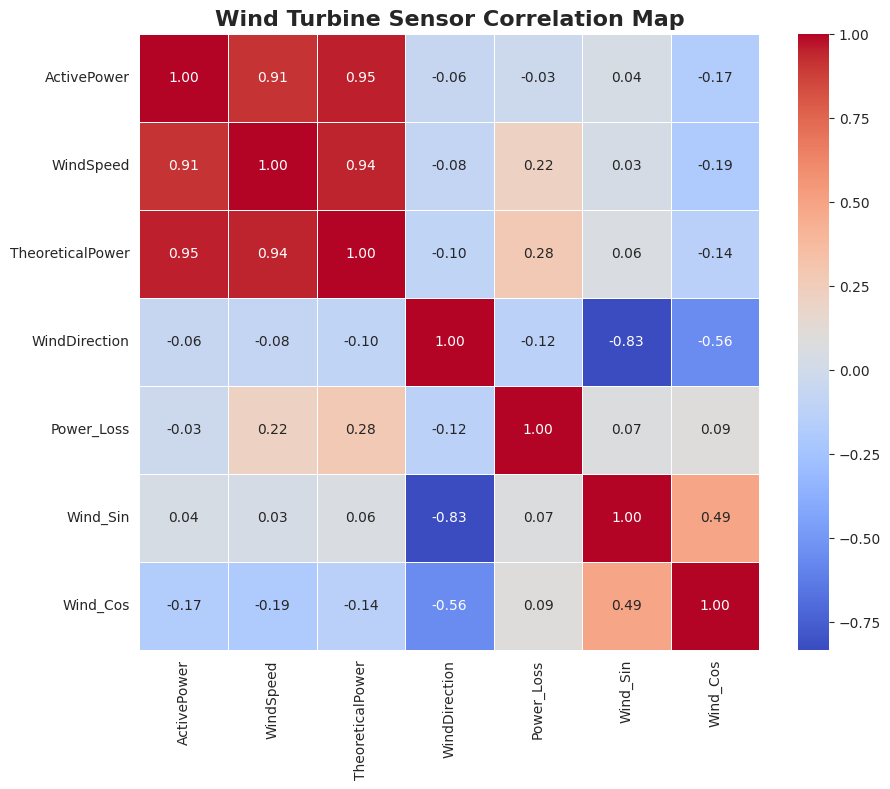

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

print("🧩THE CORRELATION MATRIX...\n")

# We have to drop 'Date' because the math formula can't multiply timestamps
heatmap_data = df.drop(columns=['Date'])

plt.figure(figsize=(10, 8))

sns.heatmap(heatmap_data.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Wind Turbine Sensor Correlation Map', fontsize=16, fontweight='bold')
plt.show()

In [ ]:
# The Rule: If the wind is strong (> 3.5 m/s) but power is dead (<= 10 kW), it's a broken dot
# We are keeping everything that is NOT broken.
df_healthy = df[~((df['WindSpeed'] > 3.5) & (df['ActivePower'] <= 10))]

print(f"Original Messy Data: {len(df)} rows")
print(f"Clean Healthy Data: {len(df_healthy)} rows")
print(f"Dots Removed: {len(df) - len(df_healthy)} anomalies isolated for later!")

Original Messy Data: 50530 rows
Clean Healthy Data: 48228 rows
Dots Removed: 2302 anomalies isolated for later!


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Select the Inputs (X) and the Target (y) from our CLEAN dataset
X_healthy = df_healthy[['WindSpeed', 'Wind_Sin', 'Wind_Cos']]
y_healthy = df_healthy['ActivePower']

# 2. Split into 80% Study Material (Train) and 20% Final Exam (Test)
X_train, X_test, y_train, y_test = train_test_split(X_healthy, y_healthy, test_size=0.2, random_state=42)

# 3. Build the AI Brain (100 Decision Trees voting together)
rf_pure = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

print("🧠 AI is studying perfect aerodynamics (Training)...")
rf_pure.fit(X_train, y_train)

# 4. Take the Exam!
print("📝 AI is taking the Final Exam (Predicting)...")
y_pred = rf_pure.predict(X_test)

# 5. Grade the AI's Exam
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f} kW")
print(f"Accuracy (R-Squared): {r2*100:.2f}%")

🧠 AI is studying perfect aerodynamics (Training)...
📝 AI is taking the Final Exam (Predicting)...
Mean Absolute Error (MAE): 101.52 kW
Accuracy (R-Squared): 96.27%


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

print(" INITIATING HYPERPARAMETER TUNING \n")

# The Menu of Options for the AI
param_grid = {
    'n_estimators': [100, 200, 300],          # Size of the engineer team
    'max_depth': [10, 15, 20, 25, None],      # How deep they can think
    'min_samples_split': [2, 5, 10],          # The brakes to stop overfitting
    'min_samples_leaf': [1, 2, 4]             # Minimum dots per leaf
}


rf_base = RandomForestRegressor(random_state=42)

# n_iter=10 means it will test 10 random combinations from the menu above
rf_tuner = RandomizedSearchCV(estimator=rf_base, param_distributions=param_grid,
                              n_iter=10, cv=3, random_state=42, n_jobs=-1, verbose=2)

rf_tuner.fit(X_train, y_train)

# Extract the Champion AI
rf_optimized = rf_tuner.best_estimator_

print(f"Best Settings Found: {rf_tuner.best_params_}\n")

y_pred_opt = rf_optimized.predict(X_test)
opt_mae = mean_absolute_error(y_test, y_pred_opt)
opt_r2 = r2_score(y_test, y_pred_opt)

print(f" NEW Optimized MAE: {opt_mae:.2f} kW")
print(f" NEW Optimized Accuracy: {opt_r2*100:.2f}%")

 INITIATING HYPERPARAMETER TUNING 

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Settings Found: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 10}

 NEW Optimized MAE: 94.83 kW
 NEW Optimized Accuracy: 96.66%


In [ ]:
# 1. Grab the exact same features, but from the FULL MESSY dataset
X_full = df[['WindSpeed', 'Wind_Sin', 'Wind_Cos']]

# 2. The Digital Twin predicts what the power SHOULD be based on physics
print("🧠 AI is calculating baseline physics for all 50,530 rows...")
df['Expected_Power_kW'] = rf_optimized.predict(X_full)

# 3. Calculate the Anomaly Score (Expectation vs Reality)
# If the AI expects 3500 kW, but Reality is 0 kW... the Deviation is 3500!
df['Power_Deviation_kW'] = df['Expected_Power_kW'] - df['ActivePower']

print("the worst-case scenario:")
max_failure = df['Power_Deviation_kW'].max()
print(f"Maximum Power Deviation (Biggest Anomaly): {max_failure:.2f} kW")

🧠 AI is calculating baseline physics for all 50,530 rows...
the worst-case scenario:
Maximum Power Deviation (Biggest Anomaly): 3596.18 kW


In [ ]:
df.head()

,Date,ActivePower,WindSpeed,TheoreticalPower,WindDirection,Power_Loss,Wind_Sin,Wind_Cos,Expected_Power_kW,Power_Deviation_kW
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,36.281117,-0.984792,-0.173736,360.933097,-19.114694
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,66.148316,-0.999719,-0.023715,365.447568,-88.321628
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,84.523429,-0.998998,0.044749,330.247372,23.870785
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,96.481664,-0.999759,0.021956,355.493737,-64.152168
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,111.052276,-0.997151,-0.075426,407.807975,27.157279


Total Alarms Triggered in one year: 2043 times


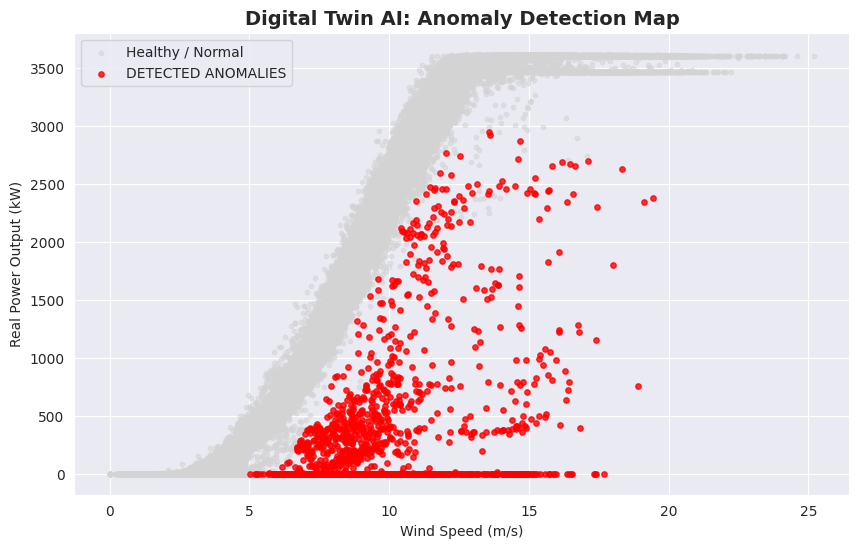

In [ ]:
import matplotlib.pyplot as plt

# 1. The Threshold: We only ring the alarm if the turbine loses more than 500 kW
threshold = 500

# 2. Create the final Alarm column (1 = Broken, 0 = Healthy)
# If Deviation is greater than 500, label it as an Anomaly (1)
df['Anomaly_Alarm'] = (df['Power_Deviation_kW'] > threshold).astype(int)

# 3. Count the Alarms
total_alarms = df['Anomaly_Alarm'].sum()
print(f"Total Alarms Triggered in one year: {total_alarms} times")

plt.figure(figsize=(10, 6))

# Plot the Healthy Data (Grey)
plt.scatter(df['WindSpeed'][df['Anomaly_Alarm'] == 0],
            df['ActivePower'][df['Anomaly_Alarm'] == 0],
            color='lightgrey', alpha=0.5, label='Healthy / Normal', s=10)

# Plot the Anomalies the AI caught! (Red)
plt.scatter(df['WindSpeed'][df['Anomaly_Alarm'] == 1],
            df['ActivePower'][df['Anomaly_Alarm'] == 1],
            color='red', alpha=0.8, label='DETECTED ANOMALIES', s=15)

plt.title('Digital Twin AI: Anomaly Detection Map', fontsize=14, fontweight='bold')
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Real Power Output (kW)')
plt.legend()
plt.show()

BUILDING THE ANOMALY CLASSIFIER...

📉 Before SMOTE: 1596 Anomalies vs 38828 Healthy
📈 After SMOTE: 38828 Anomalies vs 38828 Healthy

🧠 Classifier is studying the SMOTE-balanced data...
📝 Taking the final exam...

📊 CLASSIFIER REPORT CARD:
              precision    recall  f1-score   support

           0       0.98      0.85      0.91      9659
           1       0.15      0.55      0.23       447

    accuracy                           0.84     10106
   macro avg       0.56      0.70      0.57     10106
weighted avg       0.94      0.84      0.88     10106



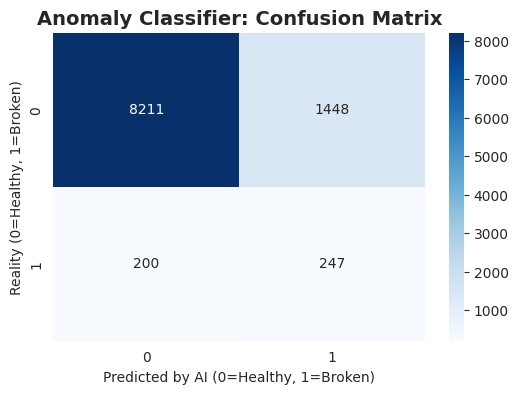

In [ ]:
#Early Warning System
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt

print("BUILDING THE ANOMALY CLASSIFIER...\n")

# 1. The Features (Environment) and the Target (The Alarm we built)
X = df[['WindSpeed', 'Wind_Sin', 'Wind_Cos']]
y = df['Anomaly_Alarm']

# 2. Split the data FIRST (Never SMOTE the test data)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"📉 Before SMOTE: {sum(y_train==1)} Anomalies vs {sum(y_train==0)} Healthy")

# 3. Apply SMOTE to balance the training classroom
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"📈 After SMOTE: {sum(y_train_smote==1)} Anomalies vs {sum(y_train_smote==0)} Healthy")

# 4. Train
anomaly_classifier = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
print("\n🧠 Classifier is studying the SMOTE-balanced data...")
anomaly_classifier.fit(X_train_smote, y_train_smote)

# 5. Take the Final Exam
print("📝 Taking the final exam...")
y_pred = anomaly_classifier.predict(X_test)

# 6. The Final Report & Confusion Matrix
print("\n📊 CLASSIFIER REPORT CARD:")
print(classification_report(y_test, y_pred))

# Draw the Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Anomaly Classifier: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted by AI (0=Healthy, 1=Broken)')
plt.ylabel('Reality (0=Healthy, 1=Broken)')
plt.show()

APPLYING THE FIX...

📉 Total Strict Anomalies in Training Data: 1050

🧠 AI is studying with 'Balanced Subsample' weights...
📝 Taking the strictly graded exam...

📊 REFINED CLASSIFIER:
              precision    recall  f1-score   support

           0       0.98      0.93      0.96      9822
           1       0.16      0.48      0.24       284

    accuracy                           0.92     10106
   macro avg       0.57      0.70      0.60     10106
weighted avg       0.96      0.92      0.94     10106



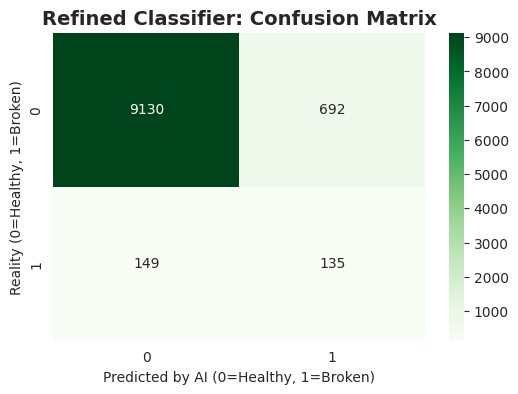

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

print("APPLYING THE FIX...\n")

# 1. Update the Threshold to only catch Catastrophic Failures (No more 500kW stutters)
NEW_THRESHOLD = 1000
df['Strict_Anomaly_Alarm'] = (df['Power_Deviation_kW'] > NEW_THRESHOLD).astype(int)

# 2. Re-Split the Data with the NEW strict labels

X = df[['WindSpeed', 'Wind_Sin', 'Wind_Cos']]
y_strict = df['Strict_Anomaly_Alarm']

X_train_strict, X_test_strict, y_train_strict, y_test_strict = train_test_split(X, y_strict, test_size=0.2, random_state=42)

X_train_strict, X_test_strict, y_train_strict, y_test_strict = train_test_split( X, y_strict, test_size=0.2, random_state=42)

print(f"📉 Total Strict Anomalies in Training Data: {sum(y_train_strict==1)}")

# 3. The Refined Classifier (No SMOTE, just Class Weights)
print("\n🧠 AI is studying with 'Balanced Subsample' weights...")
guardian_refined = RandomForestClassifier(n_estimators=200, max_depth=15,class_weight='balanced_subsample', random_state=42, n_jobs=-1)

guardian_refined.fit(X_train_strict, y_train_strict)

# 4. The Final Exam
print("📝 Taking the strictly graded exam...")
y_pred_refined = guardian_refined.predict(X_test_strict)

# 5. The New Report Card
print("\n📊 REFINED CLASSIFIER:")
print(classification_report(y_test_strict, y_pred_refined))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test_strict, y_pred_refined), annot=True, fmt='d', cmap='Greens')
plt.title('Refined Classifier: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted by AI (0=Healthy, 1=Broken)')
plt.ylabel('Reality (0=Healthy, 1=Broken)')
plt.show()

In [ ]:
#FEATURE ENGINEERING TIME-SERIES FEATURES
# 1. Calculate the 3-Hour Rolling Average (The Trend)
#6 rows = 1 hour (60 minutes).
#18 rows = 3 hours.
# 1. Calculate the 3-Hour Rolling Average (The Trend)
df['Wind_3hr_Avg'] = df['WindSpeed'].rolling(window=18).mean()

# 2. Calculate the 3-Hour Rolling Standard Deviation (The Turbulence/Stress)
df['Wind_3hr_Std'] = df['WindSpeed'].rolling(window=18).std()

# 3. Add the Physics Stress Multiplier (Wind Speed Cubed)
df['Wind_Power_Cubed'] = df['WindSpeed'] ** 3

# 4.Delete the 17 empty rows
df = df.dropna()

print("✅ Memory and Physics features successfully added, and NaNs cleared")

✅ Memory and Physics features successfully added, and NaNs cleared


Separating the Features and the Target...
Training in progress...

📊 ULTIMATE CLASSIFIER REPORT (MEMORY + PHYSICS + CLASS WEIGHTS):
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      9836
           1       0.24      0.57      0.34       267

    accuracy                           0.94     10103
   macro avg       0.61      0.76      0.65     10103
weighted avg       0.97      0.94      0.95     10103



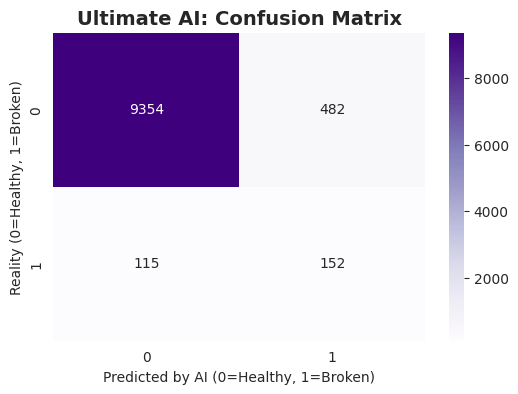

In [ ]:
print("Separating the Features and the Target...")

X_new = df[['WindSpeed', 'Wind_Sin', 'Wind_Cos', 'Wind_3hr_Avg', 'Wind_3hr_Std', 'Wind_Power_Cubed']]
y_strict = df['Strict_Anomaly_Alarm']

# Split the Data for the Final Exam
from sklearn.model_selection import train_test_split
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y_strict, test_size=0.2, random_state=42)


from sklearn.ensemble import RandomForestClassifier

guardian_ultimate = RandomForestClassifier(n_estimators=200, max_depth=15, class_weight='balanced_subsample', random_state=42, n_jobs=-1)

# Train the AI with Memory and Physics
print("Training in progress...")
guardian_ultimate.fit(X_train_new, y_train_new)

# Take the final exam
y_pred_new = guardian_ultimate.predict(X_test_new)


from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("\n📊 ULTIMATE CLASSIFIER REPORT (MEMORY + PHYSICS + CLASS WEIGHTS):")
print(classification_report(y_test_new, y_pred_new))

# Draw the Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test_new, y_pred_new), annot=True, fmt='d', cmap='Purples')
plt.title('Ultimate AI: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted by AI (0=Healthy, 1=Broken)')
plt.ylabel('Reality (0=Healthy, 1=Broken)')
plt.show()

In [ ]:
df.head()

,Date,ActivePower,WindSpeed,TheoreticalPower,WindDirection,Power_Loss,Wind_Sin,Wind_Cos,Expected_Power_kW,Power_Deviation_kW,Anomaly_Alarm,Strict_Anomaly_Alarm,Wind_3hr_Avg,Wind_3hr_Std,Wind_Power_Cubed
17,2018-01-01 02:50:00,748.229614,6.446653,785.281010,265.571808,37.051396,-0.997015,-0.077210,740.580329,-7.649286,0,0,5.867703,0.465066,267.918597
18,2018-01-01 03:00:00,736.647827,6.415083,773.172863,261.158691,36.525036,-0.988118,-0.153698,711.011995,-25.635832,0,0,5.929023,0.460132,264.001762
19,2018-01-01 03:10:00,787.246216,6.437531,781.771216,257.560211,-5.475000,-0.976523,-0.215414,733.427632,-53.818584,0,0,5.971543,0.470252,266.782906
20,2018-01-01 03:20:00,722.864075,6.220024,700.764700,255.926498,-22.099375,-0.969985,-0.243166,638.029390,-84.834685,0,0,6.027320,0.433473,240.644646
21,2018-01-01 03:30:00,935.033386,6.898026,970.736627,250.012894,35.703241,-0.939770,-0.341809,901.867313,-33.166073,0,0,6.096117,0.468543,328.227133



 THE SHAP SUMMARY PLOT:


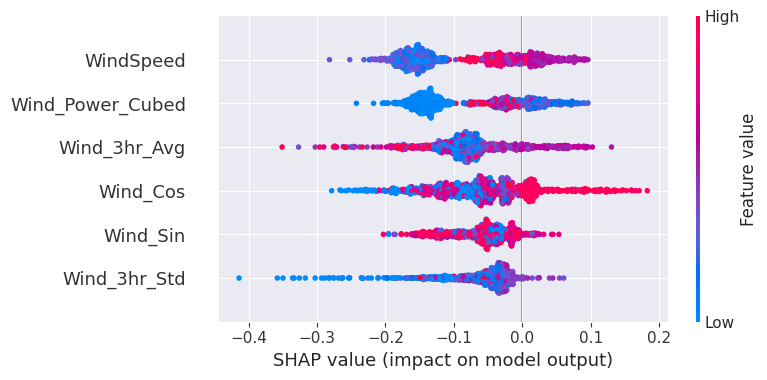

In [ ]:
# SHAP
import shap

# 1. Initialize JS for Notebooks
shap.initjs()

# 2. Build the Explainer
explainer = shap.TreeExplainer(guardian_ultimate)

# 3. Sample the test data
X_test_sample = X_test_new.sample(1000, random_state=42)
shap_values = explainer.shap_values(X_test_sample)

# 4. Draw the Plot for the 'Broken' (Class 1) alarms
print("\n THE SHAP SUMMARY PLOT:")
# (All Rows, All Columns, Class 1)
shap.summary_plot(shap_values[:, :, 1], X_test_sample)